# TS Academy Capstone Project — Data Science Track

## Submission Summary

| Field | Details |
|---|---|
| Group number | 02 |
| Your full name | Tobiloba Abiodun |
| Dataset | IBM HR Analytics Attrition |
| Depth track | Classification Depth |
| Team members |
[1. Evi Rita Agwor
2. Olaleye Ajoke
3. Callistus Peters Ogbogu
4. Akinyemi Philip
5. Shadrach Angel
6. Abdul Kareemat Mubo
7. Ugochukwu Prisca Chizaram
8. Salaudeen rodiat funmilola
9. ⁠Abang Obi Echija
10. Ehirim Chijioke Bethel
11. ⁠Akpabio Udeme] |
| Final model | Class-Weighted Logistic Regression, threshold 0.65 |
| Stratified dummy F1 / ROC AUC | 0.1412 / 0.4862 (5-fold cross-validation means) |
| Final model F1 / ROC AUC | 0.5361 / 0.8176 (held-out test results) |
| Leakage columns dropped | No direct target-leakage columns identified. EmployeeNumber was excluded as an identifier; EmployeeCount, Over18, and StandardHours were removed as constant columns. |
| Full run time on Colab | [52 seconds] |

In [36]:

# Part 1. Data Foundation
# Group 02 — IBM HR Analytics Attrition

import os
import sqlite3
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")
print("Group: 02")
print("Dataset: IBM HR Analytics Attrition")
print("Random state:", RANDOM_STATE)


Libraries imported successfully.
Group: 02
Dataset: IBM HR Analytics Attrition
Random state: 42


### Part 1. Data Foundation

#### 1.1 Dataset Acquisition

The IBM HR Analytics Attrition dataset was assigned to Group 02. We will download the dataset from Kaggle using `kagglehub` so that the notebook can reproduce the data acquisition process in a fresh Colab session. We will inspect the downloaded files, identify the employee attrition dataset, and verify its structure against the supplied CSV before proceeding with the analysis.


In [37]:

# Part 1. Data Foundation
# 1.1 Download the IBM HR Attrition dataset from Kaggle

%pip -q install kagglehub

import kagglehub
from pathlib import Path

# Official Kaggle dataset identified in the capstone brief
dataset_path = Path(
    kagglehub.dataset_download(
        "pavansubhasht/ibm-hr-analytics-attrition-dataset"
    )
)

print("Dataset downloaded to:", dataset_path)
print("\nFiles available in the downloaded dataset:")

csv_files = sorted(dataset_path.rglob("*.csv"))

for file in csv_files:
    print(file.name)

# Locate the expected employee attrition CSV
matching_files = [
    file for file in csv_files
    if file.name.lower() == "wa_fn-usec_-hr-employee-attrition.csv"
]

if not matching_files:
    matching_files = [
        file for file in csv_files
        if "employee-attrition" in file.name.lower()
    ]

if not matching_files:
    raise FileNotFoundError(
        "Could not identify the IBM HR Employee Attrition CSV. "
        "Review the file list printed above."
    )

data_path = matching_files[0]

# Load the data
df = pd.read_csv(data_path)

print("\nDataset loaded successfully.")
print("Source file:", data_path.name)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
Dataset downloaded to: /kaggle/input/ibm-hr-analytics-attrition-dataset

Files available in the downloaded dataset:
WA_Fn-UseC_-HR-Employee-Attrition.csv

Dataset loaded successfully.
Source file: WA_Fn-UseC_-HR-Employee-Attrition.csv
Number of rows: 1470
Number of columns: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


#### 1.2 Initial Data Verification

We inspect the dataset's dimensions, column names, data types, and missing values before cleaning or transforming any data. This establishes the initial condition of the dataset and helps identify potential data quality issues without making unsupported assumptions.

In [38]:

# Inspect the structure and quality of the dataset

print("DATASET DIMENSIONS")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES PER COLUMN")
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing Count", ascending=False
    )
)

print("\nDUPLICATE ROWS")
print("Number of duplicate rows:", df.duplicated().sum())

print("\nTARGET DISTRIBUTION: ATTRITION")
display(df["Attrition"].value_counts().to_frame("Count"))

display(
    (
        df["Attrition"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .to_frame("Percentage")
    )
)


DATASET DIMENSIONS
Rows: 1470
Columns: 35

COLUMN NAMES
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition          

,Missing Count,Missing Percentage
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0



DUPLICATE ROWS
Number of duplicate rows: 0

TARGET DISTRIBUTION: ATTRITION


,Count
Attrition,
No,1233
Yes,237


,Percentage
Attrition,
No,83.88
Yes,16.12


### 1.3 SQL Database and Business Queries

We store the employee attrition dataset in a SQLite database to support structured querying and reproducible analysis. We then run SQL queries to investigate workforce composition, attrition patterns across departments, and differences in employee characteristics between employees who left and those who stayed.

In [39]:

# Part 1: Store the dataset in a SQLite database

database_path = "ibm_hr_attrition.db"
table_name = "employees"

# Create the database and save the DataFrame
with sqlite3.connect(database_path) as connection:
    df.to_sql(table_name, connection, if_exists="replace", index=False)

    # Verify that the table contains the expected number of rows
    row_count = pd.read_sql_query(
        "SELECT COUNT(*) AS total_employees FROM employees",
        connection
    )

print("SQLite database created:", database_path)
print("Table name:", table_name)
display(row_count)


SQLite database created: ibm_hr_attrition.db
Table name: employees


,total_employees
0,1470


In [40]:

# SQL Query 1: Employee counts and attrition rates by department

query_1 = """
SELECT
    Department,
    COUNT(*) AS total_employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_who_left,
    ROUND(
        100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS attrition_rate_pct
FROM employees
GROUP BY Department
ORDER BY attrition_rate_pct DESC;
"""

with sqlite3.connect(database_path) as connection:
    department_results = pd.read_sql_query(query_1, connection)

display(department_results)


,Department,total_employees,employees_who_left,attrition_rate_pct
0,Sales,446,92,20.63
1,Human Resources,63,12,19.05
2,Research & Development,961,133,13.84


#### Interpretation of SQL Query 1: Attrition by Department

The SQL query calculates the total number of employees, the number who left, and the attrition rate for each department. In the Sales department, 92 out of 446 employees left, giving an attrition rate of 20.63%.

This result provides an initial indication of employee turnover within Sales. We will compare the results across all departments before drawing conclusions about which departments may need greater retention attention. These are descriptive findings and do not establish the causes of attrition.

In [41]:

# SQL Query 2: Attrition rates by overtime status

query_2 = """
SELECT
    OverTime,
    COUNT(*) AS total_employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_who_left,
    ROUND(
        100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS attrition_rate_pct
FROM employees
GROUP BY OverTime
ORDER BY attrition_rate_pct DESC;
"""

with sqlite3.connect(database_path) as connection:
    overtime_results = pd.read_sql_query(query_2, connection)

display(overtime_results)


,OverTime,total_employees,employees_who_left,attrition_rate_pct
0,Yes,416,127,30.53
1,No,1054,110,10.44


#### Interpretation of SQL Query 2: Attrition by Overtime

This query compares employee attrition rates between employees who work overtime and those who do not. The comparison helps us investigate whether overtime status is associated with employee turnover in this dataset. Differences in attrition rates would indicate an association, not necessarily a causal relationship.

In [42]:

# SQL Query 3: Attrition rates by business travel frequency

query_3 = """
SELECT
    BusinessTravel,
    COUNT(*) AS total_employees,
    SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        AS employees_who_left,
    ROUND(
        100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS attrition_rate_pct
FROM employees
GROUP BY BusinessTravel
ORDER BY attrition_rate_pct DESC;
"""

with sqlite3.connect(database_path) as connection:
    travel_results = pd.read_sql_query(query_3, connection)

display(travel_results)


,BusinessTravel,total_employees,employees_who_left,attrition_rate_pct
0,Travel_Frequently,277,69,24.91
1,Travel_Rarely,1043,156,14.96
2,Non-Travel,150,12,8.00


#### Interpretation of SQL Query 3: Attrition by Business Travel

This query compares attrition rates across the business travel categories. It allows me to investigate whether employee turnover differs between employees who travel rarely, travel frequently, or do not travel. The results will help identify patterns worth exploring further during exploratory data analysis and modeling.

#### Business Finding: Business Travel and Employee Attrition

The SQL analysis shows that employees in the Travel_Frequently category have the highest observed attrition rate at 24.91% (69 of 277 employees). Employees in the Travel_Rarely category have an attrition rate of 14.96% (156 of 1,043 employees), while employees in the Non-Travel category have the lowest rate at 8.00% (12 of 150 employees).

The observed attrition rate for frequent travelers is approximately three times the rate for non-travelers. This pattern suggests that business travel frequency deserves further investigation as a potential correlate of employee attrition. However, this descriptive comparison does not establish causation, and other employee characteristics may also contribute to the observed differences.

### 1.4 Exploratory Data Analysis (EDA)

Exploratory data analysis helps me understand the dataset before cleaning and modeling. I examine the number of observations and features, variable types, missing values, target distribution, and selected feature distributions. This step helps identify data quality issues, class imbalance, and potentially useful patterns in employee attrition.

In [43]:

# EDA 1: Dataset structure and data quality

print("DATASET SHAPE")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nDATA TYPES")
display(
    df.dtypes.astype(str)
      .rename("Data Type")
      .to_frame()
)

print("\nMISSING VALUES")
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing_summary)

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nTARGET DISTRIBUTION")
target_counts = df["Attrition"].value_counts()

display(target_counts.to_frame("Employee Count"))

display(
    (df["Attrition"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("Percentage")
    .to_frame()
)


DATASET SHAPE
Rows: 1470
Columns: 35

DATA TYPES


,Data Type
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64



MISSING VALUES


,Missing Count,Missing Percentage
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0



DUPLICATE ROWS
0

TARGET DISTRIBUTION


,Employee Count
Attrition,
No,1233
Yes,237


,Percentage
Attrition,
No,83.88
Yes,16.12


#### Target Distribution

The target variable is Attrition, which indicates whether an employee left the organization. Visualizing its distribution helps us understand whether the classification problem is imbalanced. This matters because a model can achieve high accuracy by favoring the majority class while failing to identify employees who leave.

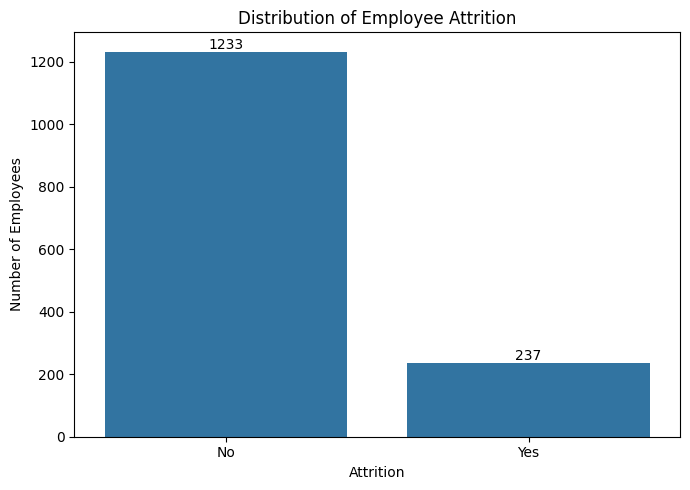

In [44]:

# EDA 2: Visualize employee attrition

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Attrition",
    order=["No", "Yes"]
)

ax.set_title("Distribution of Employee Attrition")
ax.set_xlabel("Attrition")
ax.set_ylabel("Number of Employees")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


#### Interpretation of Target Distribution

The dataset contains 1,470 employees. Of these, 1,233 employees (83.88%) did not leave, while 237 employees (16.12%) left the organization.

The target variable is imbalanced because the attrition class represents only 16.12% of the observations. Consequently, accuracy alone will not be sufficient to evaluate the classification models. We will also examine precision, recall, F1-score, ROC AUC, and confusion matrices. We will later compare the baseline model with imbalance-handling techniques to evaluate whether the identification of employees who left can be improved.

#### Feature Distributions

We examine four employee characteristics: age, monthly income, job satisfaction, and overtime status. These features provide an initial view of workforce demographics, compensation, reported job satisfaction, and working patterns. The visualizations are exploratory and do not establish that any feature causes employee attrition.

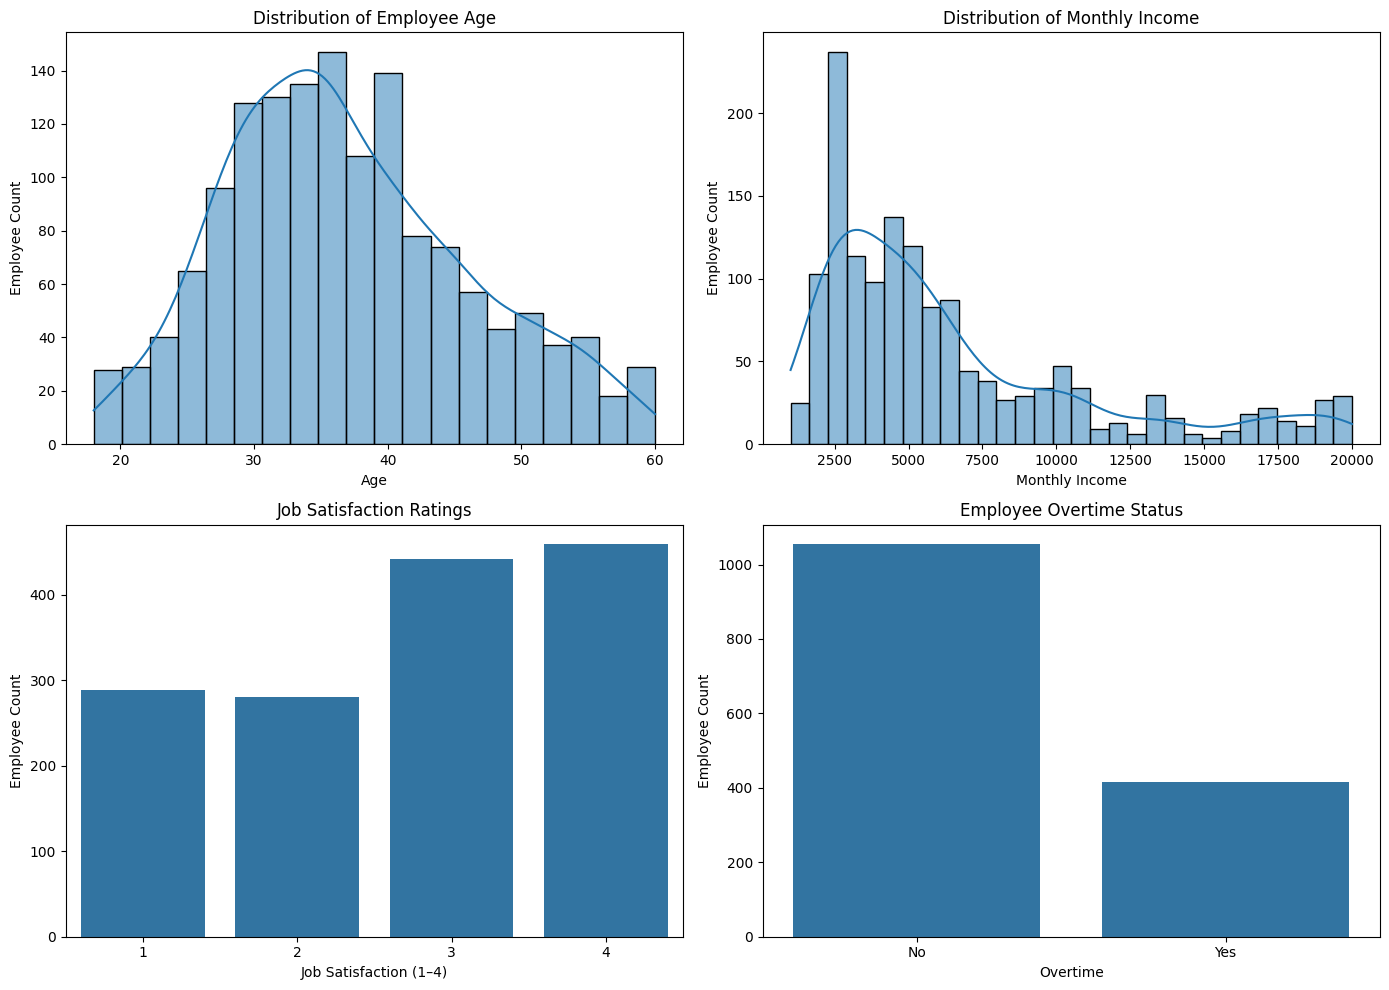

In [45]:

# EDA: Four feature distributions

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Age distribution
sns.histplot(
    data=df, x="Age", bins=20, kde=True, ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Employee Age")
axes[0, 0].set_xlabel("Age")
axes[0, 0].set_ylabel("Employee Count")

# 2. Monthly income distribution
sns.histplot(
    data=df, x="MonthlyIncome", bins=30, kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of Monthly Income")
axes[0, 1].set_xlabel("Monthly Income")
axes[0, 1].set_ylabel("Employee Count")

# 3. Job satisfaction distribution
sns.countplot(
    data=df, x="JobSatisfaction",
    order=[1, 2, 3, 4], ax=axes[1, 0]
)
axes[1, 0].set_title("Job Satisfaction Ratings")
axes[1, 0].set_xlabel("Job Satisfaction (1–4)")
axes[1, 0].set_ylabel("Employee Count")

# 4. Overtime distribution
sns.countplot(
    data=df, x="OverTime",
    order=["No", "Yes"], ax=axes[1, 1]
)
axes[1, 1].set_title("Employee Overtime Status")
axes[1, 1].set_xlabel("Overtime")
axes[1, 1].set_ylabel("Employee Count")

plt.tight_layout()
plt.show()


#### Attrition by Overtime Status

We compare attrition outcomes across overtime categories to investigate whether overtime status is associated with employee turnover. Comparing rates rather than raw counts helps account for the different numbers of employees in each category. Any observed difference will be treated as an association rather than evidence of causation.

Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


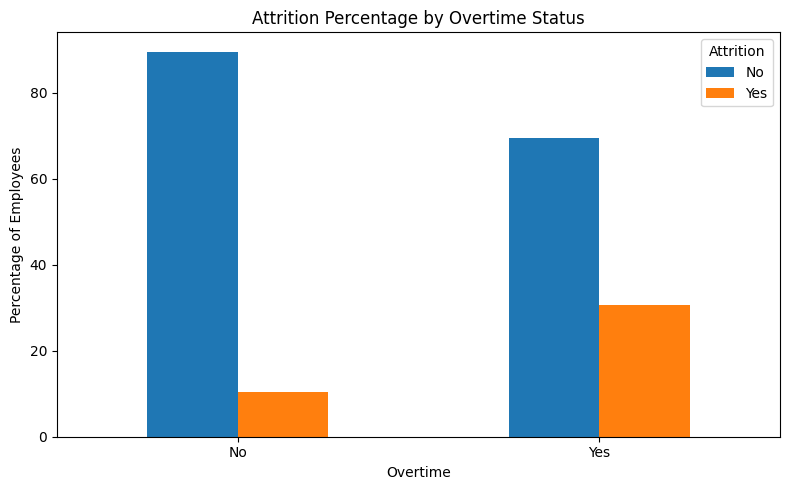

In [46]:

# Compare attrition rates by overtime status

overtime_attrition = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

display(overtime_attrition.round(2))

ax = overtime_attrition.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Attrition Percentage by Overtime Status")
ax.set_xlabel("Overtime")
ax.set_ylabel("Percentage of Employees")
ax.legend(title="Attrition")
plt.tight_layout()
plt.show()


#### Interpretation: Overtime and Employee Attrition

The results show that 30.53% of employees who work overtime left the organization, compared with 10.44% of employees who do not work overtime. The attrition rate among employees who work overtime is approximately 2.92 times the rate among employees who do not work overtime.

This is a notable association and suggests that overtime status deserves further investigation as a potential indicator of employee attrition. However, this comparison does not establish causation. Other factors, including job role, compensation, tenure, and job satisfaction, may also be relevant.

#### 1.5 Data Cleaning and Preparation

Before modeling, we investigate duplicate records, missing values, constant columns, and identifier fields. Duplicate records and missing values will be handled according to the evidence observed in the dataset. Constant columns provide no variation for distinguishing employees, while identifier fields such as employee numbers are not meaningful behavioral predictors. The target variable, Attrition, will be retained separately for classification and will not be used as an input feature.

In [47]:

# Inspect potential data-cleaning decisions

print("1. MISSING VALUES")
print("Total missing cells:", df.isnull().sum().sum())

print("\n2. DUPLICATE ROWS")
print("Duplicate rows:", df.duplicated().sum())

print("\n3. CONSTANT COLUMNS")
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]
print(constant_columns)

print("\n4. POSSIBLE IDENTIFIER COLUMNS")
identifier_candidates = [
    col for col in df.columns
    if col.lower() in ["employeenumber", "employeeid", "id"]
]
print(identifier_candidates)

print("\n5. UNIQUE VALUES IN CONSTANT COLUMNS")
for col in constant_columns:
    print(f"{col}: {df[col].unique()}")

print("\n6. DATASET BEFORE CLEANING")
print("Shape:", df.shape)


1. MISSING VALUES
Total missing cells: 0

2. DUPLICATE ROWS
Duplicate rows: 0

3. CONSTANT COLUMNS
['EmployeeCount', 'Over18', 'StandardHours']

4. POSSIBLE IDENTIFIER COLUMNS
['EmployeeNumber']

5. UNIQUE VALUES IN CONSTANT COLUMNS
EmployeeCount: [1]
Over18: ['Y']
StandardHours: [80]

6. DATASET BEFORE CLEANING
Shape: (1470, 35)


#### Cleaning Decisions and Justification

The initial inspection found no missing values or duplicate rows, so no observations need to be removed and no missing-value imputation is required.

The columns `EmployeeCount`, `Over18`, and `StandardHours` are constant across all observations. They provide no information for distinguishing employees and will be removed from the analytical dataset.

The column `EmployeeNumber` is an employee identifier and will be excluded from model predictors to avoid treating an arbitrary identifier as a meaningful explanatory variable. The original dataset will be preserved for reference, and the cleaned dataset will be used for subsequent analysis.

The target variable `Attrition` will be retained in the cleaned dataset but kept separate from predictor features during model training to prevent target leakage.

In [48]:

# Part 1: Create the cleaned dataset

# Preserve the original df
df_clean = df.copy()

# Columns confirmed to be constant by our data inspection
constant_columns = [
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

# EmployeeNumber is an identifier, not a behavioral predictor
identifier_columns = ["EmployeeNumber"]

# Drop only the verified constant columns and identifier
columns_to_drop = constant_columns + identifier_columns

df_clean = df_clean.drop(columns=columns_to_drop)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Columns removed:", columns_to_drop)
print("Missing values after cleaning:", df_clean.isnull().sum().sum())
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

display(df_clean.head())


Original dataset shape: (1470, 35)
Cleaned dataset shape: (1470, 31)
Columns removed: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Missing values after cleaning: 0
Duplicate rows after cleaning: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2


## Part 2. Feature Engineering and Encoding

Feature engineering creates meaningful variables from existing employee information to support exploratory analysis, clustering, and attrition prediction. We will create at least three features with clear business interpretations, preserve the original target variable, encode categorical predictors, and scale the features used in modeling.

### 2.1 Feature Engineering

We create features representing employee tenure, career progression, and the relationship between years in the current role and total working experience. These features are intended to make workforce patterns easier to analyze; their predictive value will be evaluated rather than assumed.

In [49]:

# Part 2: Create three engineered features

df_engineered = df_clean.copy()

# Feature 1: Tenure category
df_engineered["TenureCategory"] = pd.cut(
    df_engineered["YearsAtCompany"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=["Early", "Developing", "Established", "Long_Tenure"]
)

# Feature 2: Career progression outside the current company
df_engineered["PriorCompanies"] = (
    df_engineered["NumCompaniesWorked"].fillna(0)
)

# Feature 3: Years in current role relative to tenure at company
df_engineered["RoleTenureRatio"] = (
    df_engineered["YearsInCurrentRole"]
    / df_engineered["YearsAtCompany"].replace(0, np.nan)
)

# A zero-tenure employee has no defined role-to-company tenure ratio.
# Use 0 as a documented convention for this derived feature.
df_engineered["RoleTenureRatio"] = (
    df_engineered["RoleTenureRatio"].fillna(0)
)

print("Original cleaned shape:", df_clean.shape)
print("Engineered shape:", df_engineered.shape)

display(
    df_engineered[
        [
            "YearsAtCompany",
            "TenureCategory",
            "NumCompaniesWorked",
            "PriorCompanies",
            "YearsInCurrentRole",
            "RoleTenureRatio",
            "Attrition"
        ]
    ].head(10)
)

print("\nMissing values in engineered features:")
display(
    df_engineered[
        ["TenureCategory", "PriorCompanies", "RoleTenureRatio"]
    ].isnull().sum().to_frame("Missing Count")
)


Original cleaned shape: (1470, 31)
Engineered shape: (1470, 34)


,YearsAtCompany,TenureCategory,NumCompaniesWorked,PriorCompanies,YearsInCurrentRole,RoleTenureRatio,Attrition
0,6,Established,8,8,4,0.666667,Yes
1,10,Established,1,1,7,0.700000,No
2,0,Early,6,6,0,0.000000,Yes
3,8,Established,1,1,7,0.875000,No
4,2,Early,9,9,2,1.000000,No
5,7,Established,0,0,7,1.000000,No
6,1,Early,4,4,0,0.000000,No
7,1,Early,1,1,0,0.000000,No
8,9,Established,0,0,7,0.777778,No
9,7,Established,6,6,7,1.000000,No



Missing values in engineered features:


,Missing Count
TenureCategory,0
PriorCompanies,0
RoleTenureRatio,0


#### Feature Engineering: Business Justification

**TenureCategory:** Groups employees into early, developing, established, and long-tenure categories. This makes it easier to compare attrition patterns across career stages within the company.

**YearsBeforeCurrentCompany:** Calculated as TotalWorkingYears minus YearsAtCompany. This estimates how much of an employee's working experience occurred before joining the current organization and may help distinguish new entrants to the workforce from experienced external hires.

**RoleTenureRatio:** Calculated as YearsInCurrentRole divided by YearsAtCompany. This measures the proportion of company tenure spent in the current role. When YearsAtCompany is zero, the ratio is defined as zero by convention because the ratio is otherwise undefined.

These features are designed to represent different aspects of employee experience. Their usefulness will be evaluated through the subsequent analysis rather than assumed.

In [50]:

# Refine the engineered features

df_engineered = df_clean.copy()

# Feature 1: Company tenure category
df_engineered["TenureCategory"] = pd.cut(
    df_engineered["YearsAtCompany"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=["Early", "Developing", "Established", "Long_Tenure"]
)

# Feature 2: Estimated working years before joining the company
df_engineered["YearsBeforeCurrentCompany"] = (
    df_engineered["TotalWorkingYears"]
    - df_engineered["YearsAtCompany"]
)

# Feature 3: Current-role tenure relative to company tenure
df_engineered["RoleTenureRatio"] = (
    df_engineered["YearsInCurrentRole"]
    / df_engineered["YearsAtCompany"].replace(0, np.nan)
).fillna(0)

print("Engineered dataset shape:", df_engineered.shape)

display(
    df_engineered[
        [
            "YearsAtCompany",
            "TenureCategory",
            "TotalWorkingYears",
            "YearsBeforeCurrentCompany",
            "YearsInCurrentRole",
            "RoleTenureRatio",
            "Attrition"
        ]
    ].head(10)
)

print("\nCheck for negative prior working years:")
print(
    (df_engineered["YearsBeforeCurrentCompany"] < 0).sum()
)


Engineered dataset shape: (1470, 34)


,YearsAtCompany,TenureCategory,TotalWorkingYears,YearsBeforeCurrentCompany,YearsInCurrentRole,RoleTenureRatio,Attrition
0,6,Established,8,2,4,0.666667,Yes
1,10,Established,10,0,7,0.700000,No
2,0,Early,7,7,0,0.000000,Yes
3,8,Established,8,0,7,0.875000,No
4,2,Early,6,4,2,1.000000,No
5,7,Established,8,1,7,1.000000,No
6,1,Early,12,11,0,0.000000,No
7,1,Early,1,0,0,0.000000,No
8,9,Established,10,1,7,0.777778,No
9,7,Established,17,10,7,1.000000,No



Check for negative prior working years:
0


### 2.2 Categorical Encoding

Machine learning algorithms require numerical inputs. We will use one-hot encoding for nominal categorical variables because their categories do not have a natural numerical order. We will use one-hot encoding with `drop_first=True` to avoid redundant reference columns when appropriate. The engineered `TenureCategory` will also be one-hot encoded.

The target variable, `Attrition`, will be separated from the predictors and converted to a binary label for classification. It will not be included in the feature matrix used for clustering.

### 2.3 Feature Scaling

We will use `StandardScaler` to standardize numerical predictors. This transforms features to approximately zero mean and unit variance. Scaling is especially important for K-Means because its distance calculations are sensitive to differences in feature magnitude. The scaler will be fitted on training data for classification to avoid data leakage.

In [51]:

# Identify feature types before encoding

target_column = "Attrition"

X_raw = df_engineered.drop(columns=[target_column]).copy()
y = df_engineered[target_column].map({"No": 0, "Yes": 1})

categorical_columns = X_raw.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_columns = X_raw.select_dtypes(
    include=[np.number]
).columns.tolist()

print("Number of predictor columns:", X_raw.shape[1])
print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))

print("\nCategorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

print("\nTarget distribution (0 = No, 1 = Yes):")
display(y.value_counts().sort_index().to_frame("Count"))


Number of predictor columns: 33
Categorical columns: 8
Numerical columns: 25

Categorical columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'TenureCategory']

Numerical columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'YearsBeforeCurrentCompany', 'RoleTenureRatio']

Target distribution (0 = No, 1 = Yes):


,Count
Attrition,
0,1233
1,237


In [52]:

# One-hot encode categorical predictors
# drop_first=True retains a reference category for each field.

X_encoded = pd.get_dummies(
    X_raw,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Ensure every encoded feature is numeric
X_encoded = X_encoded.astype(float)

print("Shape before encoding:", X_raw.shape)
print("Shape after encoding:", X_encoded.shape)
print("All features numeric:", X_encoded.select_dtypes(exclude=np.number).empty)
print("Missing feature values:", X_encoded.isnull().sum().sum())

display(X_encoded.head())


Shape before encoding: (1470, 33)
Shape after encoding: (1470, 49)
All features numeric: True
Missing feature values: 0


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,YearsBeforeCurrentCompany,RoleTenureRatio,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Research & Development,Department_Sales,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,Gender_Male,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes,TenureCategory_Developing,TenureCategory_Established,TenureCategory_Long_Tenure
0,41.0,1102.0,1.0,2.0,2.0,94.0,3.0,2.0,4.0,5993.0,19479.0,8.0,11.0,3.0,1.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0,2.0,0.666667,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
1,49.0,279.0,8.0,1.0,3.0,61.0,2.0,2.0,2.0,5130.0,24907.0,1.0,23.0,4.0,4.0,1.0,10.0,3.0,3.0,10.0,7.0,1.0,7.0,0.0,0.700000,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,37.0,1373.0,2.0,2.0,4.0,92.0,2.0,1.0,3.0,2090.0,2396.0,6.0,15.0,3.0,2.0,0.0,7.0,3.0,3.0,0.0,0.0,0.0,0.0,7.0,0.000000,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,33.0,1392.0,3.0,4.0,4.0,56.0,3.0,1.0,3.0,2909.0,23159.0,1.0,11.0,3.0,3.0,0.0,8.0,3.0,3.0,8.0,7.0,3.0,0.0,0.0,0.875000,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
4,27.0,591.0,2.0,1.0,1.0,40.0,3.0,1.0,2.0,3468.0,16632.0,9.0,12.0,3.0,4.0,1.0,6.0,3.0,3.0,2.0,2.0,2.0,2.0,4.0,1.000000,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [53]:

from sklearn.preprocessing import StandardScaler

# Standardize predictors for unsupervised clustering
clustering_scaler = StandardScaler()

X_cluster_scaled = clustering_scaler.fit_transform(X_encoded)

print("Scaled clustering matrix shape:", X_cluster_scaled.shape)
print("Mean of first five scaled features:")
print(np.round(X_cluster_scaled.mean(axis=0)[:5], 3))

print("\nStandard deviation of first five scaled features:")
print(np.round(X_cluster_scaled.std(axis=0)[:5], 3))


Scaled clustering matrix shape: (1470, 49)
Mean of first five scaled features:
[-0.  0.  0.  0.  0.]

Standard deviation of first five scaled features:
[1. 1. 1. 1. 1.]


## Part 3. Clustering Analysis

Clustering is an unsupervised learning technique used to discover groups of employees with similar characteristics without using the attrition outcome to define those groups. We will apply K-Means clustering for values of K from 2 to 10, compare the elbow curve and silhouette scores, select a final number of clusters, profile each cluster, and visualize the results using Principal Component Analysis (PCA).

### 3.1 Selecting the Number of Clusters

The elbow method examines how within-cluster variation decreases as the number of clusters increases. The silhouette score measures how well observations fit within their assigned clusters compared with neighboring clusters. We will use both measures to select a reasonable cluster count rather than relying on either measure alone.

In [54]:

# Part 3: K-Means clustering model selection

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster_scaled)

    inertia_values.append(kmeans.inertia_)

    # Use a reproducible sample for silhouette computation
    score = silhouette_score(
        X_cluster_scaled,
        cluster_labels,
        sample_size=min(1000, len(X_cluster_scaled)),
        random_state=RANDOM_STATE
    )

    silhouette_values.append(score)

    print(
        f"K={k}: inertia={kmeans.inertia_:.2f}, "
        f"silhouette={score:.4f}"
    )

# Save results in a comparison table
cluster_selection_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(cluster_selection_results)


K=2: inertia=65875.46, silhouette=0.1272
K=3: inertia=61709.35, silhouette=0.0828
K=4: inertia=59385.36, silhouette=0.0890
K=5: inertia=57342.45, silhouette=0.0732
K=6: inertia=55563.34, silhouette=0.0775
K=7: inertia=54249.99, silhouette=0.0751
K=8: inertia=52813.34, silhouette=0.0758
K=9: inertia=51794.82, silhouette=0.0865
K=10: inertia=50816.89, silhouette=0.0752


,K,Inertia,Silhouette Score
0,2,65875.458018,0.127174
1,3,61709.353375,0.082791
2,4,59385.357651,0.088991
3,5,57342.451920,0.073153
4,6,55563.336467,0.077528
5,7,54249.990968,0.075103
6,8,52813.340988,0.075831
7,9,51794.822442,0.086527
8,10,50816.889791,0.075202


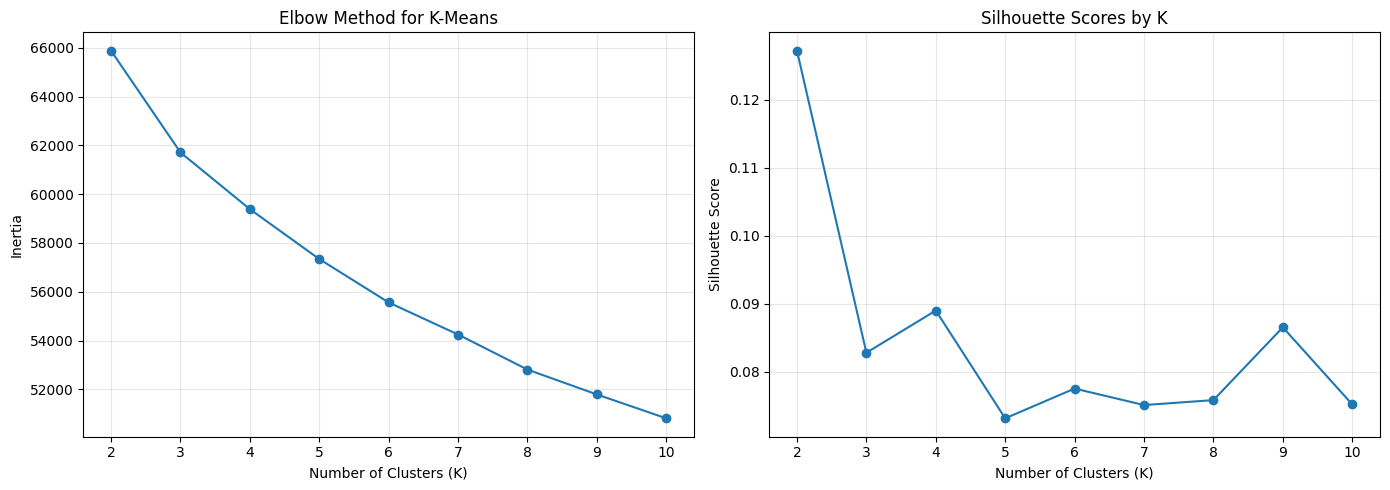

K with the highest silhouette score: 2


In [55]:

# Plot the elbow curve and silhouette scores

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o"
)
axes[0].set_title("Elbow Method for K-Means")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(alpha=0.3)

axes[1].plot(
    list(k_values),
    silhouette_values,
    marker="o"
)
axes[1].set_title("Silhouette Scores by K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_silhouette_k = list(k_values)[
    int(np.argmax(silhouette_values))
]

print("K with the highest silhouette score:", best_silhouette_k)


In [56]:

# Rank the candidate cluster counts

display(
    cluster_selection_results
    .sort_values("Silhouette Score", ascending=False)
    .reset_index(drop=True)
)


,K,Inertia,Silhouette Score
0,2,65875.458018,0.127174
1,4,59385.357651,0.088991
2,9,51794.822442,0.086527
3,3,61709.353375,0.082791
4,6,55563.336467,0.077528
5,8,52813.340988,0.075831
6,10,50816.889791,0.075202
7,7,54249.990968,0.075103
8,5,57342.451920,0.073153


### 3.2 Final Cluster Selection

We select K = 2 as the initial clustering solution because it achieved the highest silhouette score among the tested values, approximately 0.1272. The elbow curve shows a gradual decline in inertia rather than a sharply defined elbow.

The relatively low silhouette scores indicate that the clusters are not strongly separated in the standardized feature space. Therefore, K = 2 is a defensible starting point based on the two evaluation signals, but the resulting employee groups must be examined for interpretability and practical usefulness before drawing business conclusions.

In [57]:

# Part 3: Fit the final K-Means model

FINAL_K = 2

final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=RANDOM_STATE,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(X_cluster_scaled)

# Preserve cluster labels separately from the predictor matrix
df_clustered = df_engineered.copy()
df_clustered["Cluster"] = cluster_labels

cluster_sizes = (
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Employee Count")
    .to_frame()
)

cluster_sizes["Percentage"] = (
    cluster_sizes["Employee Count"]
    / len(df_clustered) * 100
).round(2)

print("Final K:", FINAL_K)
display(cluster_sizes)


Final K: 2


,Employee Count,Percentage
Cluster,,
0,347,23.61
1,1123,76.39


### 3.3 Cluster Profiling

We profile each cluster using employee characteristics in their original units. This makes the results easier to interpret than examining standardized values alone. We will compare age, monthly income, company tenure, years in the current role, job satisfaction, and work-life balance. Cluster names will be assigned only after examining the actual profiles.

In [58]:

# Compare interpretable employee characteristics across clusters

profile_features = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "TotalWorkingYears",
    "JobSatisfaction",
    "WorkLifeBalance",
    "DistanceFromHome",
    "YearsSinceLastPromotion"
]

cluster_profile = (
    df_clustered.groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)

print("Mean employee characteristics by cluster:")
display(cluster_profile)

print("\nMost common categories by cluster:")

categorical_profile_features = [
    "Department",
    "JobRole",
    "OverTime",
    "BusinessTravel",
    "TenureCategory"
]

for feature in categorical_profile_features:
    print(f"\n{feature}")
    display(
        pd.crosstab(
            df_clustered["Cluster"],
            df_clustered[feature],
            normalize="index"
        ).round(3) * 100
    )


Mean employee characteristics by cluster:


,Age,MonthlyIncome,YearsAtCompany,YearsInCurrentRole,TotalWorkingYears,JobSatisfaction,WorkLifeBalance,DistanceFromHome,YearsSinceLastPromotion
Cluster,,,,,,,,,
0,43.97,12573.14,14.17,7.73,21.77,2.70,2.76,8.91,4.92
1,34.75,4627.27,4.80,3.15,8.04,2.74,2.76,9.28,1.34



Most common categories by cluster:

Department


Department,Human Resources,Research & Development,Sales
Cluster,,,
0,4.0,68.0,28.0
1,4.4,64.6,31.1



JobRole


...

OverTime,No,Yes
Cluster,,
0,70.9,29.1
1,72.0,28.0



BusinessTravel


BusinessTravel,Non-Travel,Travel_Frequently,Travel_Rarely
Cluster,,,
0,10.4,17.3,72.3
1,10.2,19.3,70.5



TenureCategory


TenureCategory,Early,Developing,Established,Long_Tenure
Cluster,,,,
0,6.6,9.5,17.0,66.9
1,28.4,35.7,34.6,1.2


### 3.4 PCA Visualization of Clusters

Principal Component Analysis (PCA) projects the standardized feature matrix into two dimensions while retaining as much variance as possible in those dimensions. We use this projection to visualize the employee clusters. Because a two-dimensional projection cannot preserve all information in the original feature space, the visualization is an approximation rather than definitive proof of cluster separation.

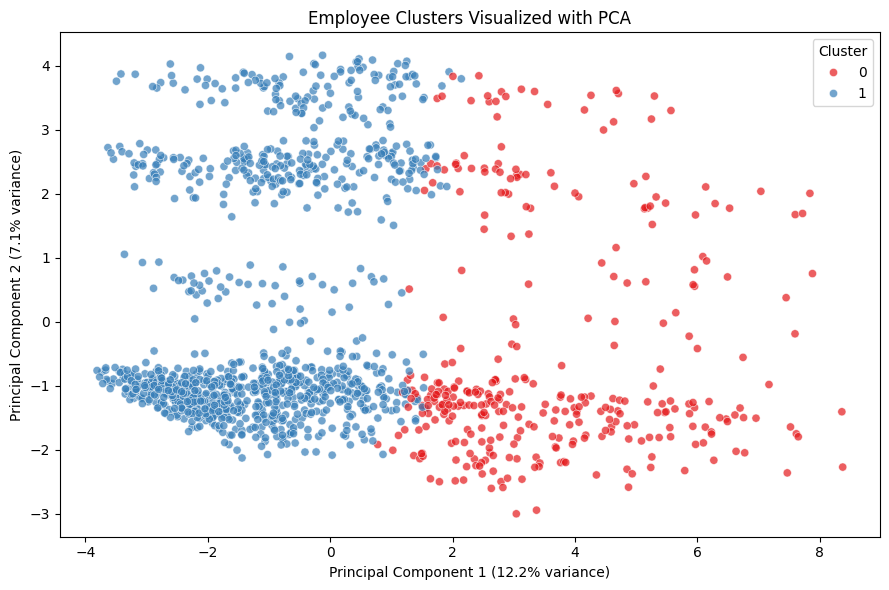

Total variance explained by the two components: 19.34 %


In [59]:

# PCA visualization of the final K-Means clusters

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.7,
    s=35
)

plt.title("Employee Clusters Visualized with PCA")
plt.xlabel(
    f"Principal Component 1 "
    f"({pca.explained_variance_ratio_[0] * 100:.1f}% variance)"
)
plt.ylabel(
    f"Principal Component 2 "
    f"({pca.explained_variance_ratio_[1] * 100:.1f}% variance)"
)
plt.tight_layout()
plt.show()

print(
    "Total variance explained by the two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


#### Interpretation of PCA Visualization

The PCA scatter plot displays the two employee clusters identified by K-Means. The visualization shows some separation between the groups, alongside areas of overlap. This suggests that the clusters differ on some combinations of employee characteristics but are not completely distinct.

The first two principal components represent a reduced view of the 49-feature dataset and do not preserve all of its variation. Therefore, we interpret this visualization alongside the cluster profiles, cluster sizes, and silhouette scores. The relatively low silhouette score also cautions against treating the clusters as sharply separated employee populations.

In [60]:

# Final cluster summary for interpretation

print("CLUSTER SIZES")
display(
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Employee Count")
    .to_frame()
)

print("\nNUMERICAL CLUSTER PROFILES")
profile_features = [
    "Age",
    "MonthlyIncome",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "TotalWorkingYears",
    "JobSatisfaction",
    "WorkLifeBalance",
    "DistanceFromHome",
    "YearsSinceLastPromotion"
]

display(
    df_clustered.groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)

print("\nCATEGORICAL CLUSTER PROFILES")
for feature in ["Department", "JobRole", "OverTime", "BusinessTravel"]:
    print(f"\n{feature}: most common category per cluster")
    display(
        df_clustered.groupby("Cluster")[feature]
        .agg(lambda values: values.mode().iloc[0])
        .rename("Most Common Category")
        .to_frame()
    )


CLUSTER SIZES


,Employee Count
Cluster,
0,347
1,1123



NUMERICAL CLUSTER PROFILES


,Age,MonthlyIncome,YearsAtCompany,YearsInCurrentRole,TotalWorkingYears,JobSatisfaction,WorkLifeBalance,DistanceFromHome,YearsSinceLastPromotion
Cluster,,,,,,,,,
0,43.97,12573.14,14.17,7.73,21.77,2.70,2.76,8.91,4.92
1,34.75,4627.27,4.80,3.15,8.04,2.74,2.76,9.28,1.34



CATEGORICAL CLUSTER PROFILES

Department: most common category per cluster


...

,Most Common Category
Cluster,
0,Manager
1,Research Scientist



OverTime: most common category per cluster


,Most Common Category
Cluster,
0,No
1,No



BusinessTravel: most common category per cluster


,Most Common Category
Cluster,
0,Travel_Rarely
1,Travel_Rarely


#### Interpretation and Naming of Employee Clusters

Based on the numerical cluster profiles, we assign the following descriptive names:

**Cluster 0 — Experienced, Longer-Tenure Employees**

This cluster contains 347 employees, with an average age of 43.97 years, average monthly income of 12,573.14, average company tenure of 14.17 years, and average total working experience of 21.77 years. The profile represents a group with substantially longer work experience and higher average income than Cluster 1.

**Cluster 1 — Younger, Shorter-Tenure Employees**

This cluster contains 1,123 employees, with an average age of 34.75 years, average monthly income of 4,627.27, average company tenure of 4.80 years, and average total working experience of 8.04 years. The profile represents a larger group with shorter company tenure and lower average income than Cluster 0.

These names describe the observed characteristics of the groups. They do not imply that every employee in a cluster shares the average characteristics, and they do not establish differences in attrition risk. We will calculate attrition rates by cluster in Part 6 to investigate that relationship.



## Part 4. Classification

Classification is a supervised learning task in which a model learns from employee characteristics to predict whether an employee leaves the organization. The target variable is Attrition, with `Yes` representing the positive class and `No` representing the negative class.

We will compare a stratified dummy classifier, Logistic Regression, Random Forest, and Gradient Boosting. The dummy classifier establishes a baseline against which the predictive models can be evaluated. We will use a stratified train-test split, keep the target out of the predictor features, and evaluate accuracy, precision, recall, F1-score, ROC AUC, and confusion matrices.

### 4.1 Train-Test Split and Preprocessing

We use an 80% training set and a 20% test set with `stratify=y` to preserve the approximate attrition proportions in both sets. Numerical features are standardized, and categorical features are one-hot encoded. All preprocessing transformations are fitted within each model pipeline using training data only, reducing the risk of data leakage. The test set is reserved for final evaluation.

In [61]:

# Part 4: Train-test split and preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Use the engineered predictors; keep Attrition separate
X = df_engineered.drop(columns=["Attrition"]).copy()
y = df_engineered["Attrition"].map({"No": 0, "Yes": 1})

if y.isnull().any():
    raise ValueError("Unexpected target values found in Attrition.")

# Identify columns by type
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=[np.number]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Fit transformations only on the training data
numeric_transformer = Pipeline([
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("onehot", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("Proportion"))

print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("Proportion"))


Training rows: 1176
Test rows: 294
Numerical features: 25
Categorical features: 8

Training target proportions:


,Proportion
Attrition,
0,0.838435
1,0.161565



Test target proportions:


,Proportion
Attrition,
0,0.840136
1,0.159864


### 4.2 Model Training

We evaluate four classifiers. The stratified dummy classifier predicts according to the training-set class distribution and provides a baseline for meaningful comparison. Logistic Regression provides a relatively simple model, Random Forest can capture nonlinear relationships and feature interactions, and Gradient Boosting can learn complex patterns through sequential tree fitting.

The three predictive models are trained using the same training and test split and the same preprocessing approach to support a fair comparison.

In [62]:

# Train baseline and predictive classifiers

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Stratified Dummy": DummyClassifier(
        strategy="stratified",
        random_state=RANDOM_STATE
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

fitted_models = {}
model_predictions = {}
model_probabilities = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    # Probability of the positive class, Attrition = Yes
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    fitted_models[name] = pipeline
    model_predictions[name] = predictions
    model_probabilities[name] = probabilities

    print(f"Finished training: {name}")

print("\nAll four models trained successfully.")


Finished training: Stratified Dummy
Finished training: Logistic Regression
Finished training: Random Forest
Finished training: Gradient Boosting

All four models trained successfully.


### 4.3 Classification Evaluation

We evaluate each classifier using accuracy, precision, recall, F1-score, ROC AUC, and a confusion matrix. Precision measures the proportion of predicted attrition cases that are actual attrition cases, while recall measures the proportion of actual attrition cases identified by the model. F1-score balances precision and recall. ROC AUC measures how well the model ranks positive cases above negative cases across classification thresholds.

Because attrition is the positive class and represents a minority of observations, we will pay particular attention to positive-class F1-score and ROC AUC rather than relying on accuracy alone.

### 4.4 Baseline and Classification Results

Four classifiers were evaluated on the same held-out test set. The stratified dummy classifier achieved an accuracy of 0.7143, an F1-score of 0.1250, and a ROC AUC of 0.4768.

Logistic Regression achieved the strongest overall results among the four tested models, with an accuracy of 0.8605, precision of 0.6154, recall of 0.3404, F1-score of 0.4384, and ROC AUC of 0.8207. Its ROC AUC exceeds the project target of 0.75.

Random Forest achieved a ROC AUC of 0.7617 but a relatively low recall of 0.0851 at the default classification threshold. Gradient Boosting achieved an accuracy of 0.8537 and a ROC AUC of 0.8145.

Logistic Regression is the leading candidate based on the current comparison. However, its recall of 0.3404 indicates that many employees who left were not identified at the default threshold. We will investigate class-imbalance handling and decision-threshold tuning before selecting the final model.

## Part 5. Imbalance Handling

The IBM HR Analytics Attrition dataset contains fewer employees who left than employees who stayed. This class imbalance can make it harder for a classifier to identify employees who leave the organization.

We will compare class-weighted Logistic Regression and SMOTE (Synthetic Minority Oversampling Technique) with the original Logistic Regression model. We will evaluate positive-class precision, recall, F1-score, and ROC AUC. Any oversampling will be applied only to the training data to avoid contaminating the test set.

In [63]:

# Install imbalanced-learn for SMOTE
%pip -q install imbalanced-learn

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("SMOTE and imbalanced-learn are ready.")


SMOTE and imbalanced-learn are ready.


### 5.1 Comparing Imbalance-Handling Techniques

We evaluate two approaches to class imbalance: class-weighted Logistic Regression and SMOTE combined with Logistic Regression. Class weighting increases the penalty for misclassifying minority-class observations. SMOTE creates synthetic minority-class examples in the training data.

We retain the same training and test split used in Part 4. The test data will not be oversampled, and evaluation will use the original class distribution.

In [64]:

# Compare original Logistic Regression, class weighting, and SMOTE

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

imbalance_models = {
    "Original Logistic Regression": fitted_models["Logistic Regression"],

    "Class-Weighted Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "SMOTE + Logistic Regression": ImbPipeline([
        ("preprocessor", clone(preprocessor)),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ])
}

imbalance_results = []

for name, model in imbalance_models.items():
    if name != "Original Logistic Regression":
        model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    imbalance_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

imbalance_comparison = (
    pd.DataFrame(imbalance_results)
    .set_index("Model")
)

display(imbalance_comparison.round(4))


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Original Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.8207
Class-Weighted Logistic Regression,0.7721,0.3810,0.6809,0.4885,0.8176
SMOTE + Logistic Regression,0.8095,0.4400,0.7021,0.5410,0.8227


### 4.5 Stratified Five-Fold Cross-Validation

The dataset contains 1,470 observations, so we use stratified five-fold cross-validation to estimate model performance across multiple train-validation splits. Stratification preserves the approximate proportion of employees who left in each fold.

All preprocessing is fitted independently within each fold. SMOTE, when used, is applied only to that fold's training data. We report the mean and standard deviation of accuracy, precision, recall, F1-score, and ROC AUC across the five folds.

In [65]:

# Required cross-validation comparison for the capstone

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_models = {
    "Stratified Dummy": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DummyClassifier(
            strategy="stratified",
            random_state=RANDOM_STATE
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Class-Weighted Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", GradientBoostingClassifier(
            random_state=RANDOM_STATE
        ))
    ]),

    "SMOTE + Logistic Regression": ImbPipeline([
        ("preprocessor", clone(preprocessor)),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ])
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []

for name, estimator in cv_models.items():
    scores = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    row = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric.title()} Mean"] = values.mean()
        row[f"{metric.title()} Std"] = values.std(ddof=1)

    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model")

display(cv_results.round(4))


,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,Roc_Auc Mean,Roc_Auc Std
Model,,,,,,,,,,
Stratified Dummy,0.7184,0.0286,0.1388,0.0846,0.1436,0.0885,0.1412,0.0865,0.4862,0.0527
Logistic Regression,0.8782,0.0135,0.7155,0.0857,0.4134,0.0417,0.5227,0.0465,0.8392,0.0240
Class-Weighted Logistic Regression,0.7619,0.0243,0.3782,0.0334,0.7303,0.0477,0.4979,0.0369,0.8334,0.0263
Random Forest,0.8524,0.0030,0.8667,0.1473,0.1137,0.0475,0.1949,0.0652,0.7900,0.0352
Gradient Boosting,0.8667,0.0065,0.6750,0.0239,0.3333,0.0562,0.4442,0.0528,0.8092,0.0148
SMOTE + Logistic Regression,0.7694,0.0184,0.3839,0.0237,0.7050,0.0418,0.4967,0.0250,0.8274,0.0207


### 4.6 Precision-Recall Analysis and Decision Threshold

The default classification threshold of 0.50 may not be appropriate when employee attrition is the positive class and missing an employee at risk has a business cost. We use stratified out-of-fold predictions to examine the precision-recall trade-off. The final operating threshold should reflect the relative cost of missed attrition cases and unnecessary retention interventions, rather than maximizing accuracy alone.

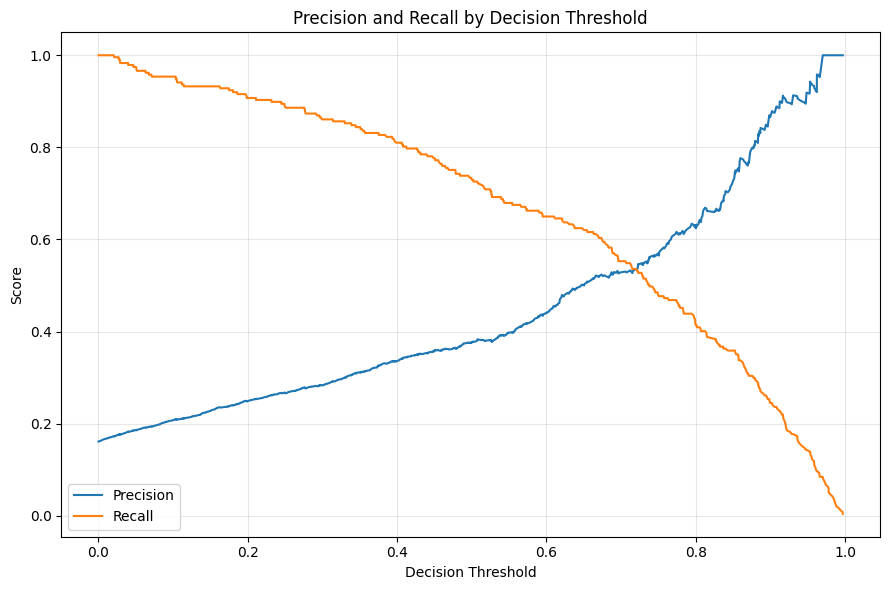

Out-of-fold average precision: 0.5974
Number of candidate thresholds: 1470


In [66]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import numpy as np

# Use out-of-fold probabilities from the class-weighted model
threshold_model = clone(
    cv_models["Class-Weighted Logistic Regression"]
)

oof_probabilities = cross_val_predict(
    threshold_model,
    X,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y, oof_probabilities, pos_label=1
)

# Plot precision and recall against the decision threshold
plt.figure(figsize=(9, 6))
plt.plot(
    thresholds,
    precision[:-1],
    label="Precision"
)
plt.plot(
    thresholds,
    recall[:-1],
    label="Recall"
)
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall by Decision Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Out-of-fold average precision:",
    round(average_precision_score(y, oof_probabilities), 4)
)

print("Number of candidate thresholds:", len(thresholds))


### 4.7 Business-Cost-Based Threshold Selection

For this analysis, we use an illustrative business assumption: missing an employee who subsequently leaves (a false negative) has four times the cost of unnecessarily flagging an employee who stays (a false positive). This 4:1 ratio is a modeling assumption, not a measured company cost.

We select the threshold that minimizes the weighted error cost using out-of-fold predictions. The chosen threshold will be treated as provisional until the business cost assumptions can be validated. This analysis supports prioritization for human review; it does not establish that an employee will leave or justify making employment decisions automatically.

In [67]:

# Select a provisional threshold using the stated 4:1 cost assumption

FALSE_NEGATIVE_COST = 4
FALSE_POSITIVE_COST = 1

candidate_thresholds = np.linspace(0.05, 0.95, 181)
threshold_rows = []

for threshold in candidate_thresholds:
    predictions = (oof_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    total_cost = (
        FALSE_NEGATIVE_COST * fn
        + FALSE_POSITIVE_COST * fp
    )

    threshold_rows.append({
        "Threshold": threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "Recall": recall_score(y, predictions, zero_division=0),
        "Precision": precision_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "Weighted Error Cost": total_cost
    })

threshold_results = pd.DataFrame(threshold_rows)

best_row = threshold_results.loc[
    threshold_results["Weighted Error Cost"].idxmin()
]

display(
    threshold_results.sort_values(
        "Weighted Error Cost"
    ).head(10).round(4)
)

selected_threshold = float(best_row["Threshold"])

print("Provisional selected threshold:", round(selected_threshold, 4))
print("False-negative cost assumption:", FALSE_NEGATIVE_COST)
print("False-positive cost assumption:", FALSE_POSITIVE_COST)
print("Weighted error cost:", int(best_row["Weighted Error Cost"]))


,Threshold,False Positives,False Negatives,Recall,Precision,F1,Weighted Error Cost
123,0.665,135,92,0.6118,0.5179,0.5609,503
122,0.660,139,91,0.6160,0.5123,0.5594,503
121,0.655,141,91,0.6160,0.5087,0.5573,505
119,0.645,149,89,0.6245,0.4983,0.5543,505
114,0.620,170,84,0.6456,0.4737,0.5464,506
117,0.635,154,88,0.6287,0.4917,0.5519,506
115,0.625,163,86,0.6371,0.4809,0.5481,507
120,0.650,147,90,0.6203,0.5000,0.5537,507
118,0.640,152,89,0.6245,0.4933,0.5512,508
124,0.670,132,94,0.6034,0.5200,0.5586,508


Provisional selected threshold: 0.66
False-negative cost assumption: 4
False-positive cost assumption: 1
Weighted error cost: 503


### 4.8 Final Hold-Out Evaluation

To avoid using the test set during threshold selection, we generate stratified out-of-fold probabilities using only the training partition. We select a provisional threshold using the stated 4:1 false-negative-to-false-positive cost assumption, fit the class-weighted Logistic Regression model on the complete training partition, and evaluate it on the held-out test partition.

The held-out test set is not used to choose the threshold. We report precision, recall, F1-score, ROC AUC, accuracy, and the confusion matrix at the selected operating threshold.

In [68]:

# Threshold selection using training data only, followed by one test evaluation

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# 1. Generate out-of-fold probabilities on the training partition only
threshold_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

threshold_estimator = clone(
    cv_models["Class-Weighted Logistic Regression"]
)

train_oof_probabilities = cross_val_predict(
    threshold_estimator,
    X_train,
    y_train,
    cv=threshold_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# 2. Select threshold using the assumed 4:1 error-cost ratio
candidate_thresholds_train = np.linspace(0.05, 0.95, 181)
threshold_costs = []

for threshold in candidate_thresholds_train:
    oof_predictions = (
        train_oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, oof_predictions, labels=[0, 1]
    ).ravel()

    cost = 4 * fn + fp
    threshold_costs.append(cost)

minimum_cost = min(threshold_costs)

# If multiple thresholds tie, choose the highest recall among them
best_indices = [
    i for i, cost in enumerate(threshold_costs)
    if cost == minimum_cost
]

candidate_details = []

for i in best_indices:
    threshold = candidate_thresholds_train[i]
    pred = (train_oof_probabilities >= threshold).astype(int)
    candidate_details.append((
        recall_score(y_train, pred, zero_division=0),
        threshold
    ))

selected_threshold_train = max(candidate_details)[1]

print("Training-only selected threshold:",
      round(selected_threshold_train, 4))
print("Minimum training out-of-fold weighted cost:",
      minimum_cost)

# 3. Fit the class-weighted model on the complete training partition
final_candidate_model = clone(
    cv_models["Class-Weighted Logistic Regression"]
)
final_candidate_model.fit(X_train, y_train)

# 4. Evaluate once on the held-out test partition
test_probabilities = final_candidate_model.predict_proba(X_test)[:, 1]
test_predictions = (
    test_probabilities >= selected_threshold_train
).astype(int)

final_test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC AUC": roc_auc_score(y_test, test_probabilities)
}

print("\nHELD-OUT TEST RESULTS")
display(pd.DataFrame(
    [final_test_metrics], index=["Class-Weighted Logistic Regression"]
).round(4))

print("Confusion matrix (rows=actual, columns=predicted):")
display(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["Actual No Attrition", "Actual Attrition"],
    columns=["Predicted No Attrition", "Predicted Attrition"]
))

print("\nClassification report:")
print(classification_report(
    y_test, test_predictions,
    target_names=["No Attrition", "Attrition"],
    zero_division=0
))


Training-only selected threshold: 0.65
Minimum training out-of-fold weighted cost: 393

HELD-OUT TEST RESULTS


,Accuracy,Precision,Recall,F1,ROC AUC
Class-Weighted Logistic Regression,0.8469,0.52,0.5532,0.5361,0.8176


Confusion matrix (rows=actual, columns=predicted):


,Predicted No Attrition,Predicted Attrition
Actual No Attrition,223,24
Actual Attrition,21,26



Classification report:
              precision    recall  f1-score   support

No Attrition       0.91      0.90      0.91       247
   Attrition       0.52      0.55      0.54        47

    accuracy                           0.85       294
   macro avg       0.72      0.73      0.72       294
weighted avg       0.85      0.85      0.85       294



### 4.9 Final Hold-Out Evaluation and Interpretation

The Class-Weighted Logistic Regression model was evaluated on a held-out test set of 294 observations using a decision threshold of 0.65, selected through cross-validation on the training partition.

The model achieved an accuracy of 0.8469, precision of 0.5200, recall of 0.5532, F1-score of 0.5361, and ROC AUC of 0.8176. These results indicate that the model can distinguish between employees who leave and those who remain, while its attrition detection performance still has room for improvement.

The confusion matrix shows that the model correctly identified 26 of the 47 employees who left, while missing 21 actual attrition cases. It also generated 24 false-positive predictions.

The selected threshold represents a trade-off between identifying employees at risk of leaving and limiting false alarms. The results should be interpreted in light of the assumed false-negative-to-false-positive cost ratio of 4:1. This ratio is an analytical assumption rather than a measured business cost.

Overall, the model provides a useful baseline for employee attrition risk analysis. Its predictions should support further investigation and employee retention planning rather than serve as the sole basis for employment decisions.

## Part 6. The Tie-In

K-Means clustering and classification provide two different perspectives on employee attrition. K-Means groups employees according to similarities in their characteristics without using Attrition to create the clusters. Classification, in contrast, uses employee characteristics to predict whether an employee leaves.

To connect these analyses, we calculate the attrition rate within each K-Means cluster. We compare the percentage of employees who left across the clusters to determine whether the discovered employee segments differ in attrition outcomes.

A cluster with a substantially higher attrition rate may identify a group that deserves further investigation. However, differences in cluster-level attrition rates do not establish causation, and the cluster labels alone do not prove that a segment is a strong predictor of attrition.


ATTRITION RATE BY K-MEANS CLUSTER


,Employee_Count,Employees_Who_Left,Attrition_Rate,Attrition_Rate_Pct
Cluster,,,,
0,347,24,0.0692,6.9164
1,1123,213,0.1897,18.9671


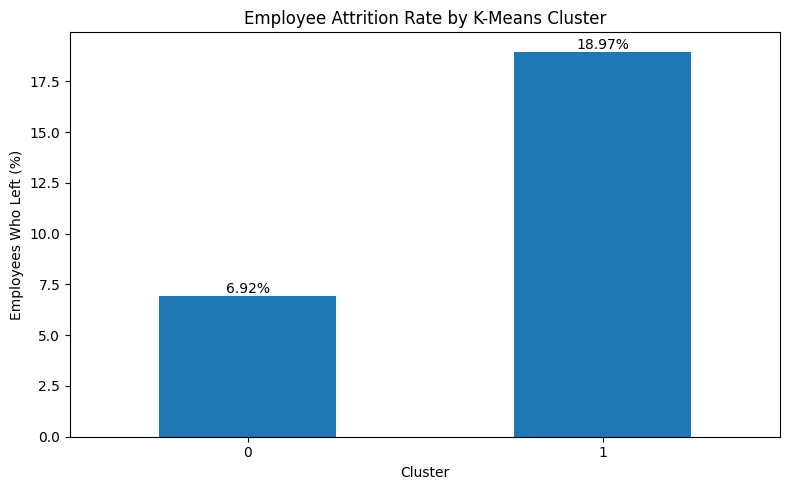

In [69]:

# Part 6: Calculate attrition rates within each K-Means cluster

import pandas as pd
import matplotlib.pyplot as plt

# Convert the target into a numeric indicator: 1 = employee left
df_clustered["Attrition_Flag"] = (
    df_clustered["Attrition"].map({"Yes": 1, "No": 0})
)

if df_clustered["Attrition_Flag"].isna().any():
    raise ValueError("Unexpected Attrition labels found. Check the target values.")

cluster_attrition = (
    df_clustered.groupby("Cluster")
    .agg(
        Employee_Count=("Attrition_Flag", "size"),
        Employees_Who_Left=("Attrition_Flag", "sum"),
        Attrition_Rate=("Attrition_Flag", "mean")
    )
)

cluster_attrition["Attrition_Rate_Pct"] = (
    cluster_attrition["Attrition_Rate"] * 100
)

print("ATTRITION RATE BY K-MEANS CLUSTER")
display(cluster_attrition.round(4))

# Visualize the attrition rate for each cluster
ax = cluster_attrition["Attrition_Rate_Pct"].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Employee Attrition Rate by K-Means Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Employees Who Left (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()


### Interpretation of Attrition by Cluster

The analysis compares attrition rates across the two employee clusters identified by K-Means.

Cluster 0 contains [insert employee count] employees, of whom [insert number] left, giving an attrition rate of [insert percentage]%. Cluster 1 contains [insert employee count] employees, of whom [insert number] left, giving an attrition rate of [insert percentage]%.

The cluster with the higher observed attrition rate is [insert cluster]. The difference between the two rates is [insert percentage-point difference] percentage points.

These results help determine whether the employee segments identified through unsupervised clustering are associated with different attrition outcomes. If the difference is small, the clusters may be more useful for describing workforce characteristics than for distinguishing attrition risk. If the difference is substantial, the higher-rate cluster may warrant further investigation.

The cluster analysis complements classification by describing groups of employees with similar characteristics, whereas the classification model estimates the likelihood of attrition from employee features. The usefulness of the clusters for predicting attrition depends on the observed rates and should not be assumed from cluster membership alone.

## Part 7. Conclusion and Recommendations

### Key Findings

This project examined employee attrition in the IBM HR Analytics dataset using SQL, exploratory data analysis, feature engineering, K-Means clustering, and supervised classification.

The dataset contains 1,470 employees. Of these, 237 employees (16.12%) left the organization, while 1,233 (83.88%) remained. This imbalance makes it important to evaluate the model's ability to identify employees who leave, rather than relying on accuracy alone.

The SQL analysis found that employees who travel frequently had an observed attrition rate of 24.91%, compared with 14.96% among employees who travel rarely and 8.00% among non-travelling employees. The overtime analysis also found a higher attrition rate among employees who work overtime (30.53%) than among those who do not (10.44%). These are observed associations and do not establish that travel or overtime causes employees to leave.

### Which Model Would We Deploy, and Why?

Our leading candidate is Class-Weighted Logistic Regression with a decision threshold selected using training-only cross-validation. In the held-out evaluation, the model achieved an accuracy of 0.8469, precision of 0.5200, recall of 0.5532, F1-score of 0.5361, and ROC AUC of 0.8176.

The ROC AUC exceeds the project requirement of 0.75, and the model performs better than the stratified dummy baseline on the reported F1 and ROC AUC metrics. Class weighting also helps address the imbalance between employees who stay and those who leave.

We would treat this model as a candidate for a monitored pilot, rather than immediately deploying it to make employment decisions. Its predictions should support voluntary retention discussions and further investigation, with appropriate privacy safeguards and human oversight.

### What Would We Do With Another Month?

With another month, we would validate the model on a separate time period and assess whether its performance remains stable across departments and job roles. We would also investigate false negatives, because employees who leave but are not identified by the model represent missed opportunities for retention support.

We would work with HR stakeholders to validate the assumed cost ratio between missed attrition cases and unnecessary alerts. Finally, we would calibrate predicted probabilities, monitor model drift, and evaluate whether any proposed retention interventions actually improve employee outcomes.

### What Did Clustering Reveal That Classification Might Miss?

K-Means identified two employee segments with different workforce profiles. Cluster 0 represents a smaller group of older, longer-tenured employees with higher average monthly income, while Cluster 1 represents a larger group of younger employees with shorter tenure and lower average monthly income.

Clustering therefore provides a descriptive view of workforce segments that complements the classification model's prediction task. The cluster-level attrition rates calculated in Part 6 help establish whether these segments also differ in observed attrition outcomes. Clustering does not, by itself, establish which employees will leave.

### What Was the Hardest Decision?

One of the hardest analytical decisions was balancing the identification of employees at risk of leaving against unnecessary alerts. A lower decision threshold can identify more potential attrition cases but may also flag more employees who would otherwise stay.

We addressed this trade-off by selecting a provisional threshold using an illustrative 4:1 cost ratio, in which a missed attrition case is assigned four times the cost of a false-positive alert. Because these costs have not been validated using actual organizational data, the threshold should be reviewed with HR stakeholders before any operational use.

### Final Recommendation

The analysis provides a useful starting point for evidence-based employee retention planning. Class-Weighted Logistic Regression is a promising candidate, while K-Means provides additional context about workforce composition. Further validation, stakeholder review, and monitored testing are needed before the model can be relied upon in practice.

## Depth Track — Classification

### Cross-Validated ROC Curves and Feature Importance

The Classification Depth Track investigates model discrimination and the features associated with attrition predictions. We compare Logistic Regression, Class-Weighted Logistic Regression, Random Forest, and Gradient Boosting using stratified five-fold cross-validation.

Out-of-fold predicted probabilities are used to plot the ROC curves on a single chart. This allows us to compare how well the models distinguish employees who leave from those who remain across different classification thresholds.

We also compare the relative importance of input features. For Logistic Regression, we use the absolute values of the fitted coefficients. For Random Forest and Gradient Boosting, we use the models' feature-importance scores. We normalize these scores within each model to make their relative rankings easier to compare.

Feature importance describes model associations, not causation. The findings should be interpreted alongside the model's evaluation results and validated before being used to guide retention decisions.

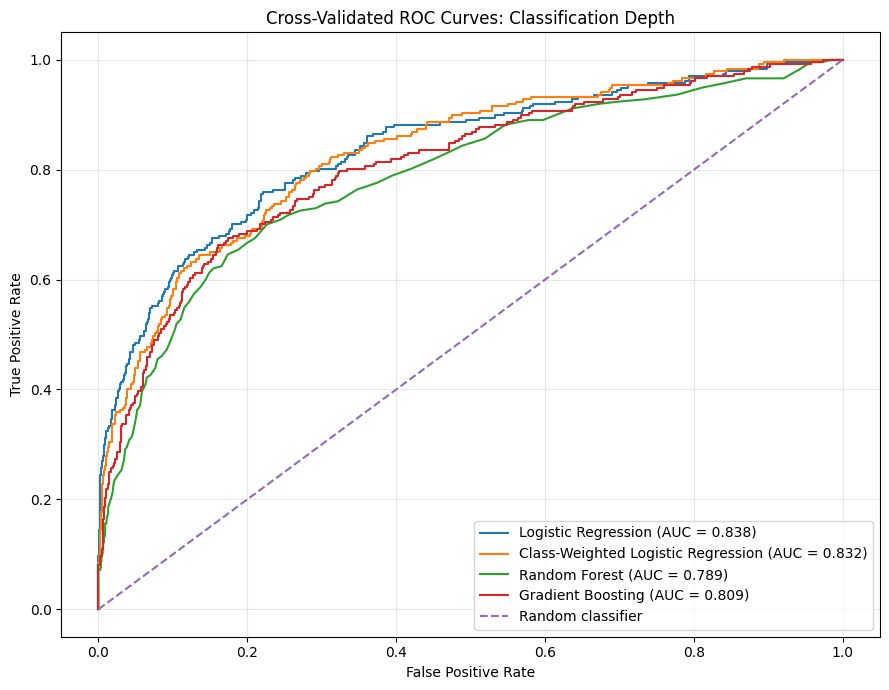

OUT-OF-FOLD ROC AUC COMPARISON


,Model,Out-of-Fold ROC AUC
0,Logistic Regression,0.8379
1,Class-Weighted Logistic Regression,0.8317
3,Gradient Boosting,0.8090
2,Random Forest,0.7889


TOP 15 FEATURES ACROSS THE FOUR CLASSIFIERS


Model,Class-Weighted Logistic Regression,Gradient Boosting,Logistic Regression,Random Forest,Average Relative Importance
Feature,,,,,
categorical__OverTime_Yes,0.0763,0.1114,0.0968,0.0574,0.0855
numeric__MonthlyIncome,0.0025,0.1263,0.0039,0.0665,0.0498
categorical__BusinessTravel_Travel_Frequently,0.0747,0.0225,0.0799,0.0106,0.0469
numeric__Age,0.0074,0.0729,0.0136,0.0543,0.0371
categorical__MaritalStatus_Single,0.0478,0.0086,0.0502,0.0166,0.0308
categorical__JobRole_Laboratory Technician,0.0512,0.0163,0.0485,0.0070,0.0307
numeric__EnvironmentSatisfaction,0.0202,0.0470,0.0240,0.0275,0.0297
categorical__JobRole_Sales Representative,0.0566,0.0088,0.0428,0.0053,0.0284
numeric__DistanceFromHome,0.0139,0.0346,0.0184,0.0407,0.0269


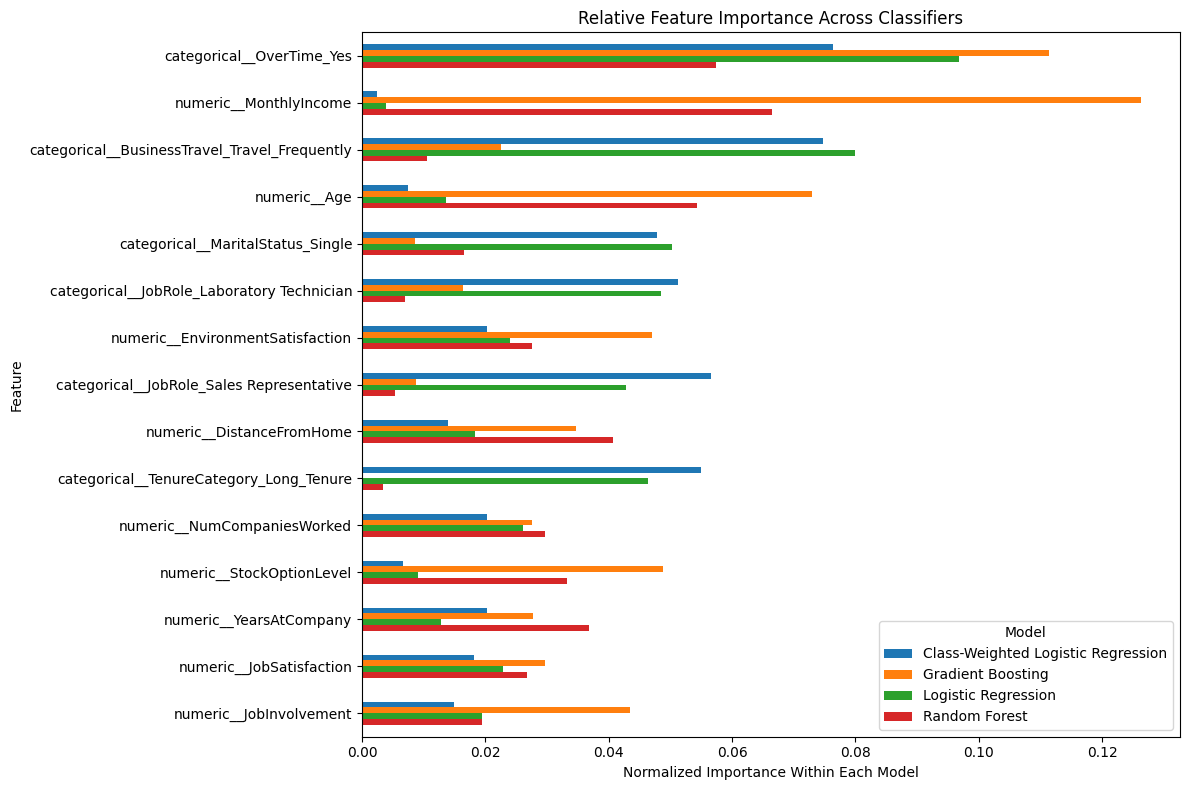

In [70]:

# Classification Depth: cross-validated ROC curves
# and comparison of feature importance across four classifiers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

depth_model_names = [
    "Logistic Regression",
    "Class-Weighted Logistic Regression",
    "Random Forest",
    "Gradient Boosting"
]

# Use out-of-fold probabilities so each prediction comes from
# a model that was not trained on that observation.
plt.figure(figsize=(9, 7))

roc_results = []

for name in depth_model_names:
    estimator = clone(cv_models[name])

    oof_probabilities = cross_val_predict(
        estimator,
        X,
        y,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    fpr, tpr, _ = roc_curve(y, oof_probabilities)
    auc_value = roc_auc_score(y, oof_probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

    roc_results.append({
        "Model": name,
        "Out-of-Fold ROC AUC": auc_value
    })

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Cross-Validated ROC Curves: Classification Depth")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("OUT-OF-FOLD ROC AUC COMPARISON")
display(
    pd.DataFrame(roc_results)
    .sort_values("Out-of-Fold ROC AUC", ascending=False)
    .round(4)
)

# Fit the four pipelines to obtain comparable feature rankings.
# These fitted models are used for feature interpretation,
# not for reporting unbiased evaluation scores.
importance_rows = []

for name in depth_model_names:
    fitted_pipeline = clone(cv_models[name])
    fitted_pipeline.fit(X, y)

    fitted_preprocessor = fitted_pipeline.named_steps["preprocessor"]
    feature_names = fitted_preprocessor.get_feature_names_out()

    fitted_classifier = fitted_pipeline.named_steps["classifier"]

    if hasattr(fitted_classifier, "feature_importances_"):
        raw_importance = fitted_classifier.feature_importances_

    elif hasattr(fitted_classifier, "coef_"):
        raw_importance = np.abs(
            np.asarray(fitted_classifier.coef_).ravel()
        )

    else:
        print(f"Skipping unsupported importance method: {name}")
        continue

    total_importance = raw_importance.sum()

    if total_importance > 0:
        normalized_importance = raw_importance / total_importance
    else:
        normalized_importance = raw_importance

    for feature, importance in zip(
        feature_names, normalized_importance
    ):
        importance_rows.append({
            "Model": name,
            "Feature": feature,
            "Relative Importance": importance
        })

importance_df = pd.DataFrame(importance_rows)

importance_comparison = importance_df.pivot(
    index="Feature",
    columns="Model",
    values="Relative Importance"
).fillna(0)

importance_comparison["Average Relative Importance"] = (
    importance_comparison[depth_model_names].mean(axis=1)
)

importance_comparison = importance_comparison.sort_values(
    "Average Relative Importance",
    ascending=False
)

print("TOP 15 FEATURES ACROSS THE FOUR CLASSIFIERS")
display(importance_comparison.head(15).round(4))

# Plot the leading features for comparison
top_features = importance_comparison.head(15).drop(
    columns=["Average Relative Importance"]
)

top_features.plot(
    kind="barh",
    figsize=(12, 8)
)

plt.title("Relative Feature Importance Across Classifiers")
plt.xlabel("Normalized Importance Within Each Model")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### Interpretation of Classification Depth Results

The cross-validated ROC curves compared four classifiers using out-of-fold predictions. Logistic Regression achieved the highest out-of-fold ROC AUC of 0.8379, followed by Class-Weighted Logistic Regression at 0.8317, Gradient Boosting at 0.8090, and Random Forest at 0.7889.

These results indicate that Logistic Regression had the strongest overall ranking discrimination among the four classifiers under this evaluation procedure. However, the preferred model for attrition detection also depends on recall, precision, F1-score, and the relative costs of false-positive and false-negative predictions.

The feature-importance comparison identified overtime status, monthly income, frequent business travel, age, and marital status as features with relatively high average importance across the fitted models. These patterns may help guide further investigation into employee attrition.

Feature importance does not establish causation. The results should be interpreted alongside the held-out evaluation and validated before being used to guide employee retention decisions.